# Delhi climate forecasting: two approaches

Run **Shared setup**, then choose **Option 1** or **Option 2**. You can also run all cells to see both results.

Both approaches use the **first 100 rows** as history and predict the **next 14 rows**. After sorting by date, the history runs from January 1 to April 10, 2017, and the checking period runs from April 11 to April 24, 2017.

Open this notebook from the project folder and use its `.venv` Python kernel. The CSV and model are already stored locally; no downloads are needed.

## Shared setup

Load the CSV, put its dates in order, and load the model once on the CPU. `history` contains the first 100 rows; `test` contains the 14 actual future rows used **only to check predictions**.

This cell does not print a result.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from timestral import TimestralForecaster

# The CSV is inside dataset/ in this project.
data = pd.read_csv("dataset/DailyDelhiClimateTest.csv")
data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date").reset_index(drop=True)

history = data.iloc[:100]
test = data.iloc[100:114]

model = TimestralForecaster.from_pretrained(
    "./models/Timestral-209M",
    device="cpu",
    local_files_only=True,
)

## Option 1: predict humidity using three helpers

Humidity is the **only target**. Temperature, wind speed, and pressure are **historical helpers** passed as `past_covariates`. Their future values are not supplied.

- `context`: shape `(1, 1, 100)` — one series, one target, 100 history steps.
- `helpers`: shape `(1, 3, 100)` — one series, three helpers, 100 history steps.

The output is a 14-row table of dates, predicted humidity, and actual humidity.

In [2]:
# One target: humidity.
context = history["humidity"].to_numpy(dtype="float32", copy=True)[None, None, :]

# Three helpers, using historical values only.
helper_columns = ["meantemp", "wind_speed", "meanpressure"]
helpers = history[helper_columns].to_numpy(dtype="float32", copy=True).T[None, :, :]

humidity_forecast = model.forecast(
    context,
    prediction_length=14,
    past_covariates=helpers,
)

humidity_result = pd.DataFrame({
    "date": test["date"].to_numpy(),
    "predicted_humidity": humidity_forecast.median[0, 0].cpu().numpy(),
    "actual_humidity": test["humidity"].to_numpy(),
})
print(humidity_result.to_string(index=False))

      date  predicted_humidity  actual_humidity
2017-04-11           23.108772        17.750000
2017-04-12           24.172440        26.000000
2017-04-13           24.336620        29.111111
2017-04-14           24.269970        37.625000
2017-04-15           24.076065        30.444444
2017-04-16           23.941269        34.250000
2017-04-17           23.795826        38.444444
2017-04-18           23.591806        27.333333
2017-04-19           23.222605        24.125000
2017-04-20           22.912983        27.500000
2017-04-21           22.560528        39.375000
2017-04-22           22.206879        40.900000
2017-04-23           21.985254        27.500000
2017-04-24           21.581959        27.142857


### Humidity graph and prediction error

This adapts the graph from `test.ipynb`: an actual line, a prediction line, and a shaded **10–90% forecast range**. The graph covers the 14 checking dates.

**Mean absolute error (MAE)** is the average distance between each prediction and its actual value. Here it is measured in humidity percentage points; lower is better.

Humidity Mean Absolute Error: 8.03 percentage points


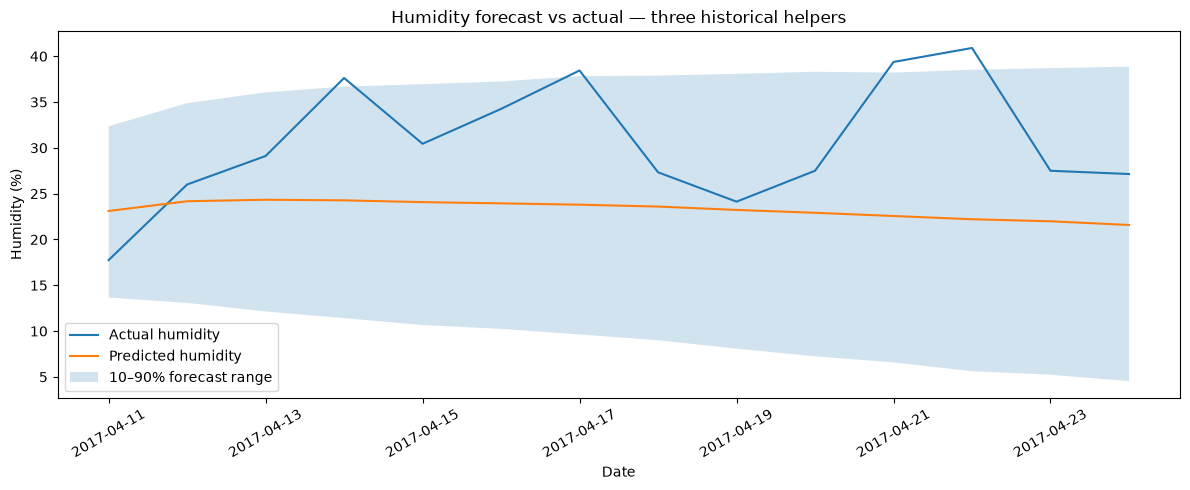

In [3]:
predicted = humidity_result["predicted_humidity"].to_numpy()
actual = humidity_result["actual_humidity"].to_numpy()
lower = humidity_forecast.quantile(0.1)[0, 0].cpu().numpy()
upper = humidity_forecast.quantile(0.9)[0, 0].cpu().numpy()
dates = humidity_result["date"]

mae = abs(predicted - actual).mean()
print(f"Humidity Mean Absolute Error: {mae:.2f} percentage points")

plt.figure(figsize=(12, 5))
plt.plot(dates, actual, label="Actual humidity")
plt.plot(dates, predicted, label="Predicted humidity")
plt.fill_between(dates, lower, upper, alpha=0.2, label="10–90% forecast range")
plt.title("Humidity forecast vs actual — three historical helpers")
plt.xlabel("Date")
plt.ylabel("Humidity (%)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Option 2: predict all four variables together

All four columns are **targets**, so this approach predicts humidity, temperature, wind speed, and pressure jointly. No separate helpers are passed.

`context` has shape `(1, 4, 100)` — one series, four targets, 100 history steps. The output is a 14-row table of dates and predicted values for all four columns.

This option only needs **Shared setup**. It does not depend on Option 1.

In [4]:
columns = ["humidity", "meantemp", "wind_speed", "meanpressure"]
context = history[columns].to_numpy(dtype="float32", copy=True).T[None, :, :]

joint_forecast = model.forecast(
    context,
    prediction_length=14,
)

joint_result = pd.DataFrame(
    joint_forecast.median[0].cpu().numpy().T,
    columns=columns,
)
joint_result.insert(0, "date", test["date"].to_numpy())
print(joint_result.to_string(index=False))

      date  humidity  meantemp  wind_speed  meanpressure
2017-04-11 22.631214 28.010927   13.825272   1007.660156
2017-04-12 23.565584 28.117825   12.810358   1007.418701
2017-04-13 23.846416 28.211868   12.444373   1007.253052
2017-04-14 23.862747 28.254738   12.244867   1007.142334
2017-04-15 23.814642 28.289644   12.128366   1007.044983
2017-04-16 23.635023 28.327124   12.086075   1006.999512
2017-04-17 23.478638 28.362007   12.095642   1006.905884
2017-04-18 23.276762 28.405893   12.133565   1006.878662
2017-04-19 22.905046 28.459372   12.156652   1006.854370
2017-04-20 22.607275 28.484985   12.195532   1006.811157
2017-04-21 22.226578 28.532314   12.210241   1006.746094
2017-04-22 21.896399 28.565105   12.199841   1006.676025
2017-04-23 21.677162 28.584103   12.189338   1006.621216
2017-04-24 21.274496 28.645546   12.247503   1006.534546


### Adjust acceptable errors

Edit the numbers below to decide how close a prediction must be to count as acceptable. The humidity starting value is **5 percentage points**, matching your example. The other starting tolerances use their columns’ own units; adjust them to suit your task.

An error **equal to or smaller than** the tolerance counts as acceptable. A tolerance of `0` counts only exact matches.

After changing a tolerance, rerun the **settings**, **metrics**, and **graph** cells below. You do not need to rerun the forecast. Changing a tolerance changes the within-tolerance percentage, **not** the predictions or MAE.

In [5]:
# Change these numbers to adjust what you consider an acceptable error.
acceptable_errors = {
    "humidity": 5.0,       # Humidity percentage points, not relative percent error.
    "meantemp": 2.0,       # Same units as the meantemp column.
    "wind_speed": 3.0,     # Same units as the wind_speed column.
    "meanpressure": 3.0,   # Same units as the meanpressure column.
}

### MAE and percentage within tolerance

**MAE (Mean Absolute Error)** is the average absolute difference between predictions and actual values. Lower is better; `0` means every evaluated prediction is exact.

For actual humidity `[80, 70, 60]` and predictions `[78, 74, 57]`, the absolute errors are `[2, 4, 3]`. MAE is `(2 + 4 + 3) / 3 = 3` humidity percentage points.

**Within-tolerance rate** is `acceptable predictions / evaluated predictions × 100`. For example, **12 out of 14** gives **85.7%**. That is an illustration; the cell below calculates the real percentage for this forecast.

The table reports both metrics for **each of the four targets**, along with the tolerance and counts. Only pairs with finite actual and predicted values are evaluated; skipped pairs are counted separately. MAE stays in each variable’s own units, so errors for different variables should not be compared as if they shared one scale.

In [6]:
from math import isfinite

errors = {}
within_tolerance = {}
metric_rows = []

for column in columns:
    tolerance = acceptable_errors[column]
    if not isfinite(tolerance) or tolerance < 0:
        raise ValueError(f"The acceptable error for {column} must be a finite number of 0 or more.")

    actual_values = test[column].to_list()
    predicted_values = joint_result[column].to_list()
    total_error = 0.0
    acceptable_count = 0
    evaluated_count = 0

    for actual, predicted in zip(actual_values, predicted_values):
        if not isfinite(actual):
            continue
        if not isfinite(predicted):
            continue

        error = abs(predicted - actual)
        total_error += error
        evaluated_count += 1
        if error <= tolerance:
            acceptable_count += 1

    if evaluated_count == 0:
        raise ValueError(f"No finite actual/predicted pairs are available for {column}.")

    mae = total_error / evaluated_count
    rate = acceptable_count / evaluated_count * 100
    errors[column] = mae
    within_tolerance[column] = rate
    metric_rows.append({
        "variable": column,
        "MAE": mae,
        "acceptable_error": tolerance,
        "within_tolerance_%": rate,
        "within_count": acceptable_count,
        "evaluated_rows": evaluated_count,
        "skipped_rows": len(actual_values) - evaluated_count,
    })

scores = pd.DataFrame(metric_rows)
rounded_scores = scores.round({"MAE": 3, "within_tolerance_%": 1})
print(rounded_scores.to_string(index=False))

humidity_mae = errors["humidity"]
humidity_rate = within_tolerance["humidity"]
humidity_tolerance = acceptable_errors["humidity"]
print(f"\nHumidity MAE: {humidity_mae:.2f} percentage points.")
print(f"{humidity_rate:.1f}% of predictions were within {humidity_tolerance} humidity percentage points of the actual readings.")

    variable   MAE  acceptable_error  within_tolerance_%  within_count  evaluated_rows  skipped_rows
    humidity 8.326               5.0                35.7             5              14             0
    meantemp 3.587               2.0                21.4             3              14             0
  wind_speed 5.086               3.0                21.4             3              14             0
meanpressure 3.823               3.0                42.9             6              14             0

Humidity MAE: 8.33 percentage points.
35.7% of predictions were within 5.0 humidity percentage points of the actual readings.


### Four graphs with both metrics

Each panel retains the actual line, prediction line, and shaded **10–90% forecast range** from the original graph style. Its title shows MAE and the percentage within your chosen tolerance.

The shaded range describes forecast uncertainty. The adjustable acceptable error is a separate rule used to evaluate predictions against actual readings.

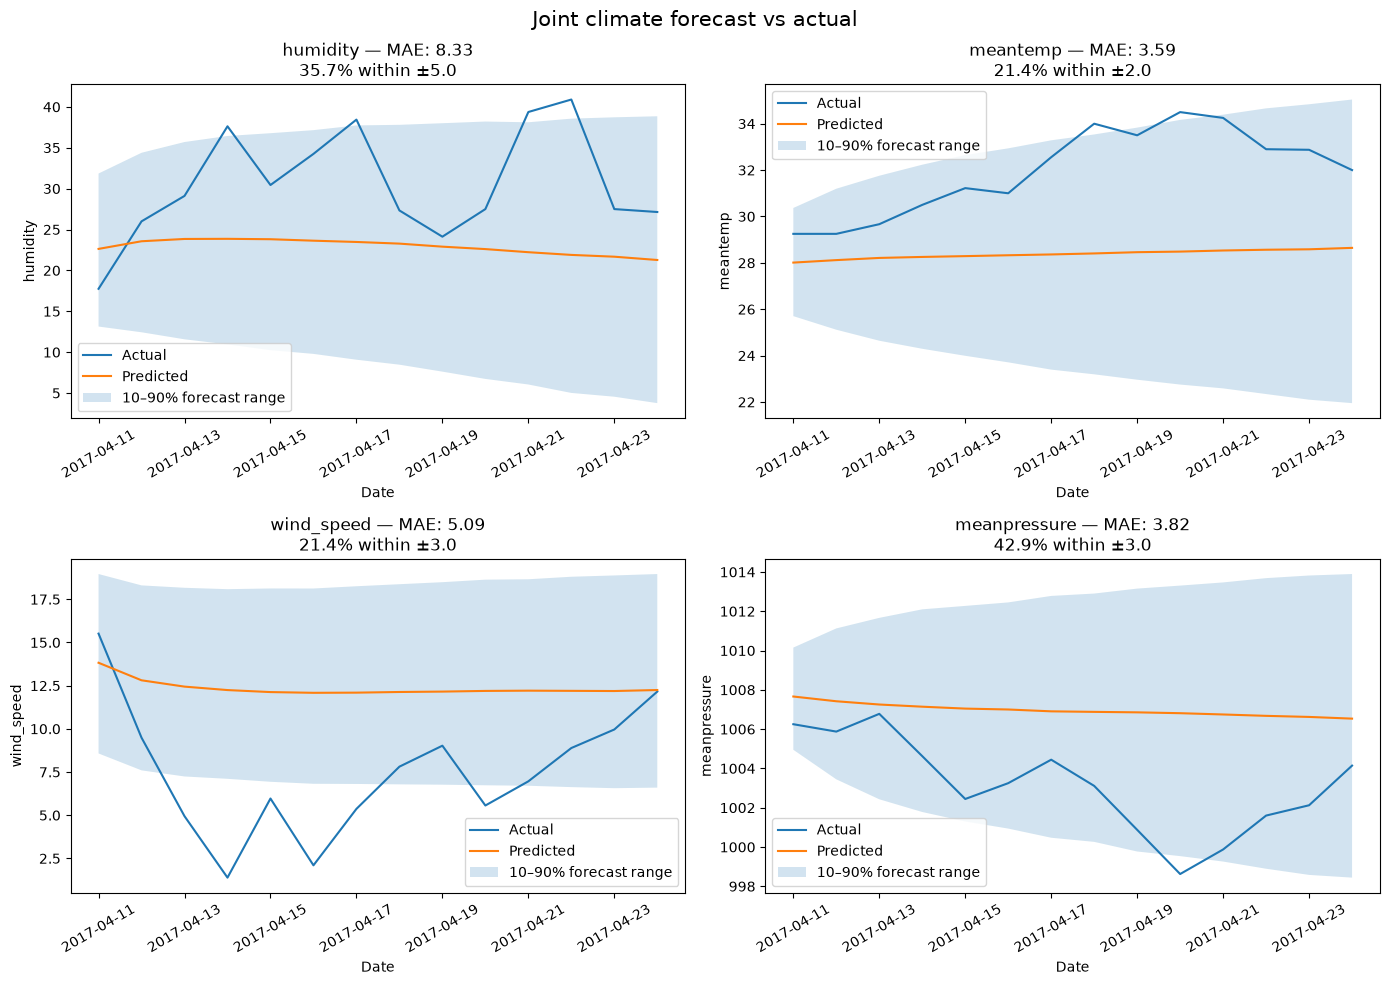

In [7]:
joint_lower = joint_forecast.quantile(0.1)[0].cpu().numpy()
joint_upper = joint_forecast.quantile(0.9)[0].cpu().numpy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for index, column in enumerate(columns):
    ax = axes.flat[index]
    ax.plot(test["date"], test[column], label="Actual")
    ax.plot(joint_result["date"], joint_result[column], label="Predicted")
    ax.fill_between(
        test["date"],
        joint_lower[index],
        joint_upper[index],
        alpha=0.2,
        label="10–90% forecast range",
    )
    mae = errors[column]
    rate = within_tolerance[column]
    tolerance = acceptable_errors[column]
    ax.set_title(f"{column} — MAE: {mae:.2f}\n{rate:.1f}% within ±{tolerance}")
    ax.set_xlabel("Date")
    ax.set_ylabel(column)
    ax.tick_params(axis="x", labelrotation=30)
    ax.legend()

fig.suptitle("Joint climate forecast vs actual", fontsize=15)
fig.tight_layout()
plt.show()

## What changes between the options?

| | Option 1 | Option 2 |
|---|---|---|
| Targets predicted | Humidity | All four variables |
| Historical helpers | Temperature, wind speed, pressure | No separate helper input |
| Future measurements passed to the model | None | None |
| History / forecast length | 100 / 14 rows | 100 / 14 rows |

Both approaches check predictions against the same held-out dates. Neither approach is guaranteed to be more accurate. The shaded ranges describe forecast uncertainty, not guaranteed outcomes.

Plotting references: [Matplotlib fill_between](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.fill_between.html) and [Matplotlib subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html).